<a href="https://colab.research.google.com/github/allnlk/ML/blob/main/%D0%9B%D0%A0_10_%D0%9A%D1%83%D0%B1%D1%80%D0%B0%D0%BA_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Кубрак Аліна
**Група:** 3-10  
**Дата:** 06.11

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [2]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow import keras
import os

# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [3]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
fashion_mnist = tf.keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

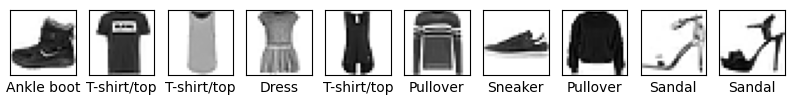

In [4]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(10,10))
for i in range(10):
  plt.subplot(1,10,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(x_train[i], cmap=plt.cm.binary)
  plt.xlabel(class_names[y_train[i]])
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [5]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train = (x_train / 255.0).astype('float32')
x_test = (x_test / 255.0).astype('float32')


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [6]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = models.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)




1. **Кількість нейронів ($256 \to 64$):**
Перший шар із $256$ нейронами розпізнає базові патерни й контури зображень Fashion MNIST ($28 \times 28$ пікселів). Другий шар стискає ці дані до $64$ нейронів, залишаючи лише найважливіші абстрактні ознаки перед фінальною класифікацією на 10 класів.
2. **Dropout ($0.3$):**
Випадково «вимикає» $30\%$ нейронів під час кожної епохи. Це змушує мережу шукати альтернативні зв'язки та запобігає перенавчанню (overfitting) на тренувальній вибірці.
3. **Швидкість навчання ($3e-4$ / $0.0003$):**
Забезпечує плавний і стабільний рух оптимізатора Adam до мінімуму втрат без ризику проскочити його чи спричинити різкі коливання точності.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [8]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
cb = [
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

history = model.fit(
    x_train, y_train,
    epochs=50,
    batch_size=128,
    validation_split=0.1,
    callbacks=cb,
    verbose=1
)

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print('Test accuracy:', test_acc)

Epoch 1/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7091 - loss: 0.8464 - val_accuracy: 0.8275 - val_loss: 0.4921 - learning_rate: 3.0000e-04
Epoch 2/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8173 - loss: 0.5328 - val_accuracy: 0.8465 - val_loss: 0.4268 - learning_rate: 3.0000e-04
Epoch 3/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8382 - loss: 0.4643 - val_accuracy: 0.8555 - val_loss: 0.3930 - learning_rate: 3.0000e-04
Epoch 4/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8491 - loss: 0.4299 - val_accuracy: 0.8643 - val_loss: 0.3768 - learning_rate: 3.0000e-04
Epoch 5/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8571 - loss: 0.4037 - val_accuracy: 0.8713 - val_loss: 0.3543 - learning_rate: 3.0000e-04
Epoch 6/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8637 - loss: 0.3856 - val_accuracy: 0.8718 - val_loss: 0.3557 - learning_rate: 3.0000e-04
Epoch 7/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy:

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [9]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 654,176 (2.50 MB)

 Trainable params: 218,058 (851.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 436,118 (1.66 MB)

### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [10]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
from google.colab import drive
drive.mount('/content/drive')
model.save('/content/drive/MyDrive/fashion_mnist_model.keras')

Mounted at /content/drive


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

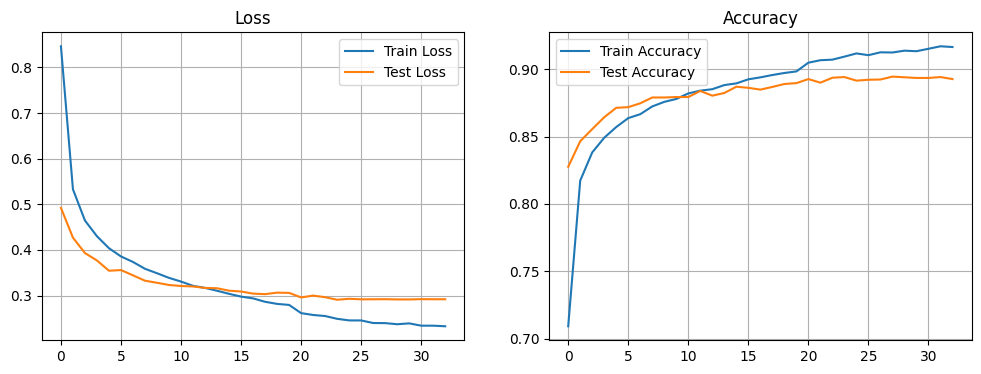

In [11]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Test Loss')
plt.title('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Test Accuracy')
plt.title('Accuracy')
plt.grid(True)
plt.legend()

plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [12]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
predictions = model.predict(x_test)

predicted_labels = np.argmax(predictions, axis=1)

print(classification_report(y_test, predicted_labels, target_names=class_names))

313/313 - 2s - 7ms/step - accuracy: 0.8909 - loss: 0.3117
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.83      0.85      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.82      0.80      0.81      1000
       Dress       0.89      0.90      0.90      1000
        Coat       0.79      0.84      0.81      1000
      Sandal       0.97      0.97      0.97      1000
       Shirt       0.73      0.69      0.71      1000
     Sneaker       0.94      0.96      0.95      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.97      0.95      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

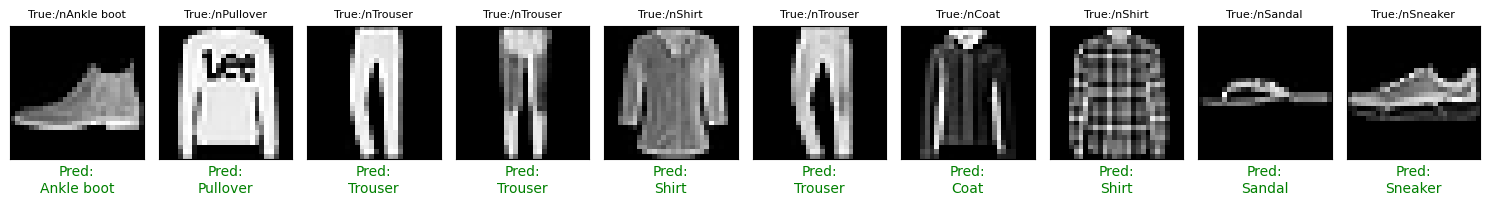

In [13]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(15, 3))

for i in range(10):
  plt.subplot(1, 10, i + 1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(x_test[i], cmap='gray')
  pred_label = class_names[predicted_labels[i]]
  true_label = class_names[y_test[i]]
  color = 'green' if predicted_labels[i] == y_test[i] else 'red'
  plt.xlabel(f'Pred:\n{pred_label}', color=color)
  plt.title(f'True:/n{true_label}', fontsize=8)

plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Характеристика класів з найбільшою кількістю помилок:
Найбільше помилок виникає на класі Shirt (Сорочка), де показник f1-score найнижчий — 0.71 (точність класифікації всього 73%, а повнота 69%). Модель часто плутає сорочки з іншими схожими верхніми елементами одягу (наприклад, T-shirt/top або Pullover), оскільки вони мають подібні силуети, а низька роздільна здатність зображень ($28 \times 28$ пікселів) ускладнює розрізнення дрібних деталей текстури та комірців. Також певні труднощі спостерігаються з категоріями Coat та Pullover.Виконання вимоги щодо мінімальної точності:
Вимогу виконано успішно: отримана тестова точність ($89.09\%$) перевищує заданий мінімальний поріг у $0.87$ ($87\%$).

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [14]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install keras-tuner -q

In [15]:
from tensorflow.keras.layers import Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import L2
from keras_tuner.tuners import RandomSearch

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow import keras
import os

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [16]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
fashion_mnist = tf.keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

x_train = x_train / 255.0
x_test = x_test / 255.0

### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [19]:
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(Flatten())

    for i in range(hp.Int('num_layers', 1, 3)):
        model.add(Dense(
            units=hp.Int('units_' + str(i), min_value=32, max_value=512, step=32),
            activation='relu',
            kernel_regularizer=L2(0.001)
        ))
        model.add(Dropout(0.2))

    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer=keras.optimizers.Adam(hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [20]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='tuner_logs',
    project_name='fashion_mnist_classification'
)

### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [22]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)

tuner.search(x_train, y_train, epochs=50, validation_data=(x_test, y_test),
             callbacks=[early_stopping, reduce_lr])

best_model = tuner.get_best_models(num_models=1)[0]
best_model.summary()

history = best_model.fit(
    x_train, y_train,
    epochs=50,
    validation_data=(x_test, y_test),
    callbacks=[early_stopping, reduce_lr]
)

Trial 3 Complete [00h 03m 55s]
val_accuracy: 0.8859999775886536

Best val_accuracy So Far: 0.8859999775886536
Total elapsed time: 00h 07m 13s


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 320)            │       251,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 352)            │       112,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 352)            │       124,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         3,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 491,978 (1.88 MB)

 Trainable params: 491,978 (1.88 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - accuracy: 0.8977 - loss: 0.3970 - val_accuracy: 0.8843 - val_loss: 0.4393 - learning_rate: 1.0000e-04
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.8992 - loss: 0.3921 - val_accuracy: 0.8823 - val_loss: 0.4368 - learning_rate: 1.0000e-04
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.8999 - loss: 0.3863 - val_accuracy: 0.8821 - val_loss: 0.4440 - learning_rate: 1.0000e-04
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9036 - loss: 0.3807 - val_accuracy: 0.8790 - val_loss: 0.4412 - learning_rate: 1.0000e-04
Epoch 5/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9039 - loss: 0.3764 - val_accuracy: 0.8871 - val_loss: 0.4219 - learning_rate: 1.0000e-04
Epoch 6/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9050 - loss: 0.3722 - val_accuracy: 0.8809 - val_loss: 0.4366 - learning_rate: 1.0000e-04
Epoch 7/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8871 - loss: 0.4219
Test accuracy: 0.8870999813079834
Test loss: 0.4218980371952057


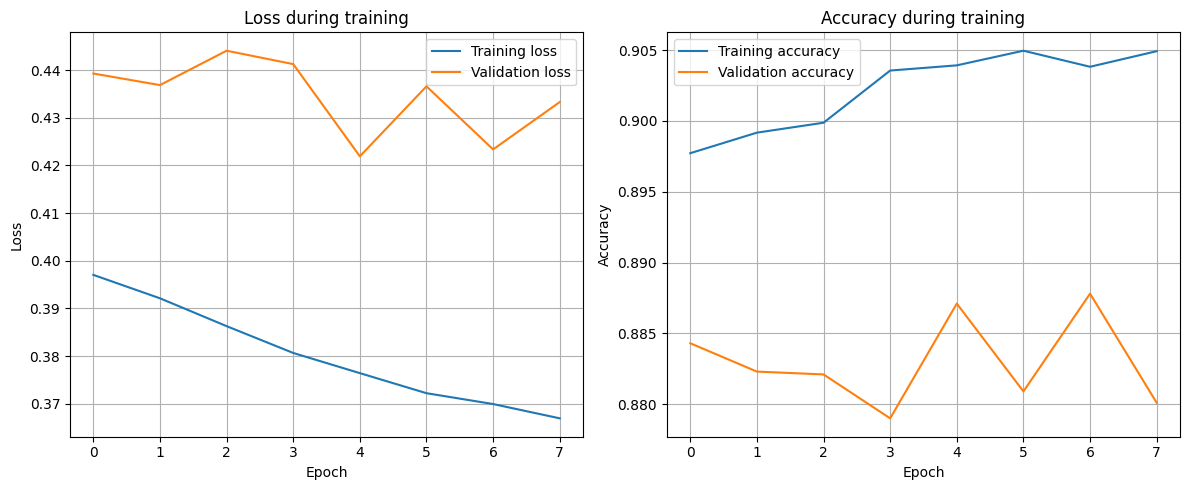

In [24]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
test_loss, test_acc = best_model.evaluate(x_test, y_test)
print('Test accuracy:', test_acc)
print('Test loss:', test_loss)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Loss during training')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('Accuracy during training')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
| :--- | :--- | :--- |
| Кількість прихованих шарів | 2 | 3 |
| Кількість нейронів | 256 / 64 | 320 / 352 / 352 |
| Швидкість навчання | 3e-4 (0.0003) | 1e-4 (0.0001) |
| Точність на тестовій вибірці (accuracy) | 0.8909 (89.09%) | 0.8871 (88.71%) |
| Втрати на тестовій вибірці (loss) | 0.3117 | 0.4219 |
| Кількість епох навчання | 33 | 8 |
**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?

Так, досягнуто. Отримана точність на тестовій вибірці становить $0.8909$ ($89.09\%$), що перевищує заданий поріг у $0.87$.

2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?

Ні, не покращила. Базова модель із першого завдання показала вищу точність ($89.09\%$) та менші втрати порівняно з найкращою моделлю після Keras Tuner ($88.71\%$).


3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?

Найкращими за результатами пошуку стали 3 приховані шари з кількістю нейронів $320$, $352$ та $352$ при швидкості навчання $1e-4$. Результати можуть відрізнятися через випадкову ініціалізацію початкових ваг нейронної мережі та стохастичність (випадковий порядок батчів) під час процесу навчання.

4. Які класи Fashion MNIST класифікувати найскладніше?

Найскладнішим для класифікації є клас Shirt (Сорочка), оскільки модель часто плутає його з іншими подібними категоріями верхнього одягу (T-shirt/top або Pullover) через схожі силуети та обмежену роздільну здатність зображень ($28 \times 28$ пікселів).


---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.